# Klasyfikacja sygnalow EKG (MIT-BIH) - 1D CNN + SVM (CS-Net)

In [21]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

from src.config import ALL_RECORDS, FULL_PATIENT_GROUPS, SAMPLE_PATIENT_GROUPS, SAMPLE_RECORDS
from src.device import setup_accelerator_and_memory
from src.preprocessing import preload_records_to_ram
from src.metadata import get_patient_statistics_table, get_group_statistics_table, get_aami_statistics_table
from src.signal_stats import get_signal_statistics_table, get_group_signal_statistics_table
from src.features import (
    build_multimodal_dataset_with_groups,
    get_feature_importance_per_group,
    get_relational_qrs_importance_table,
    run_permutation_shuffle_test,
)
from src.training import (
    compare_window_shapes,
    evaluate_hybrid_feature_csnet,
    evaluate_by_patient_groups,
    evaluate_threshold_tuning,
)
from src.evaluation import plot_confusion_matrix, get_patient_prediction_breakdown
from src.explainability import plot_model_explanations
from src.visualization import (
    plot_class_distribution,
    plot_group_mean_waveforms,
    plot_qrs_spectrum_comparison,
    plot_random_beats_side_by_side,
)

setup_accelerator_and_memory()
preload_records_to_ram(SAMPLE_RECORDS, max_workers=8)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Zaladowano do RAM: 4/4 rekordow w trybie wielowatkowym.


### 1. Statystyki wstepne: pacjenci i rozklad klas (AAMI EC57)

,ID,Grupa,Wiek,Plec,Stymulator,Norma (-1),Arytmia / Stym (+1),Razem,Udzial (+1)
0,100,Standard,69,M,Nie,2239,34,2273,1.5%
1,101,Standard,75,F,Nie,1860,5,1865,0.3%
2,102,Pacemaker,84,F,Tak,99,2032,2131,95.4%
3,104,Pacemaker,66,F,Tak,163,1400,1563,89.6%


,Grupa Pacjentow,Liczba Pacjentow,N (Norma / Bloki),S (Nadkomorowe),V (Komorowe),F (Zlane),Q (Stymulator / Nieznane),Razem Pobudzen
0,Standard (bez stymulatora),44,90125 (89.5%),2781 (2.8%),7009 (7.0%),803 (0.8%),15 (0.0%),100733
1,Pacemaker (ze stymulatorem),4,506 (5.8%),0 (0.0%),227 (2.6%),0 (0.0%),8028 (91.6%),8761


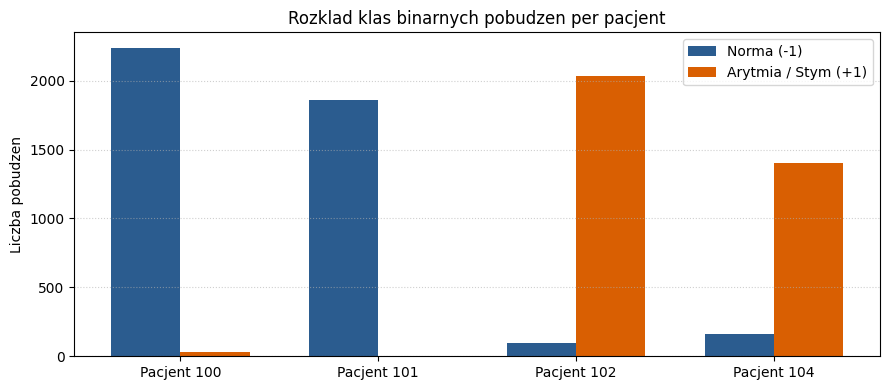

In [22]:
stats_df = get_patient_statistics_table()
aami_df = get_aami_statistics_table(FULL_PATIENT_GROUPS)
display(stats_df)
display(aami_df)
plot_class_distribution(stats_df)

### 2. Statystyki wlasciwosci sygnalow EKG dla grup

,ID,Grupa,Tetno [BPM],RR [ms],SDNN [ms],Amplituda R [mV],Szerokosc QRS [ms],Pole QRS [mV·ms],Vpp [mV],Kurtoza
0,100,Standard,75.5,794.6,48.8,6.31,34.9,177.5,25.19,27.3
1,101,Standard,62.2,964.9,79.0,5.72,26.2,160.7,19.19,25.7
2,102,Pacemaker,72.8,824.1,40.9,4.39,83.6,217.0,16.08,5.6
3,104,Pacemaker,76.5,784.3,108.2,3.58,87.0,141.6,14.02,9.3


,Grupa Pacjentow,Liczba Pacjentow,Tetno [BPM],RR [ms],SDNN [ms],Amplituda R [mV],Szerokosc QRS [ms],Pole QRS [mV·ms],Vpp [mV],Kurtoza
0,Standard (bez stymulatora),2,68.8 (+/- 9.4),879.8 (+/- 120.4),63.9 (+/- 21.4),6.01 (+/- 0.42),30.5 (+/- 6.2),169.1 (+/- 11.9),22.19 (+/- 4.24),26.5 (+/- 1.1)
1,Pacemaker (ze stymulatorem),2,74.7 (+/- 2.6),804.2 (+/- 28.1),74.5 (+/- 47.6),3.98 (+/- 0.57),85.3 (+/- 2.4),179.3 (+/- 53.3),15.05 (+/- 1.46),7.5 (+/- 2.6)


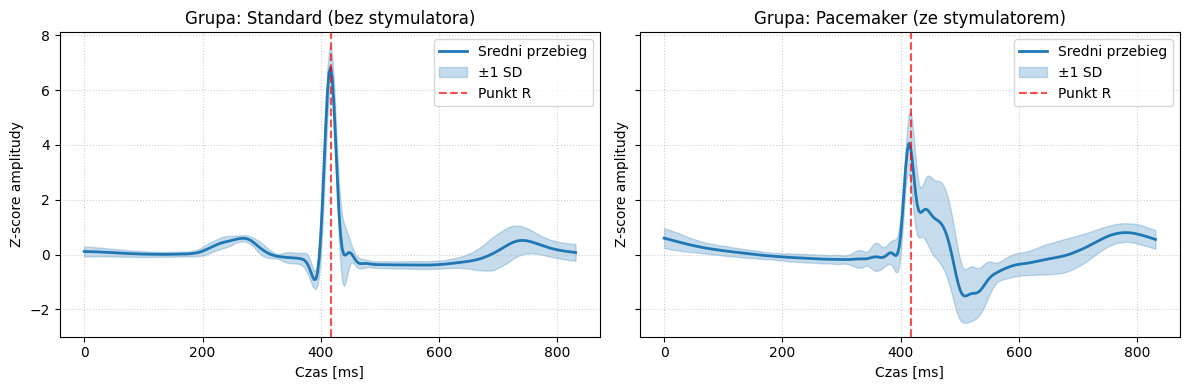

In [23]:
signal_stats_df = get_signal_statistics_table()
group_signal_df = get_group_signal_statistics_table()
display(signal_stats_df)
display(group_signal_df)
plot_group_mean_waveforms()

### 3. Analiza morfologii i widma zespolu QRS (Norma vs Stymulator)

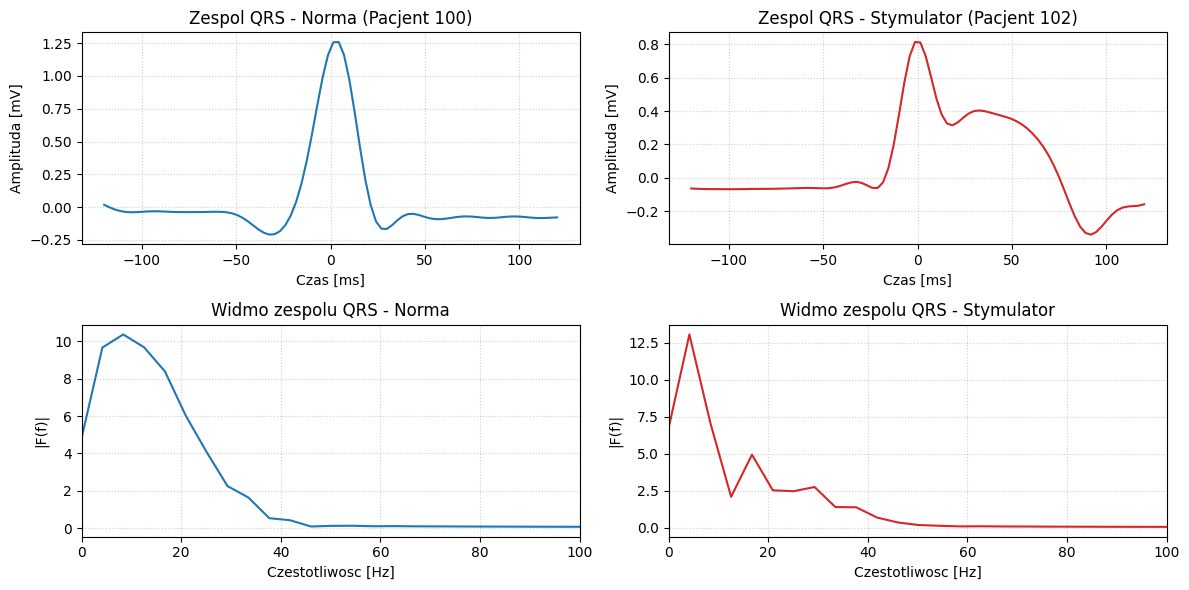

In [24]:
plot_qrs_spectrum_comparison(record_standard='100', record_paced='102')

### 4. Wizualizacja losowych pobudzen pacjenta ze stymulatorem (rekord 102)

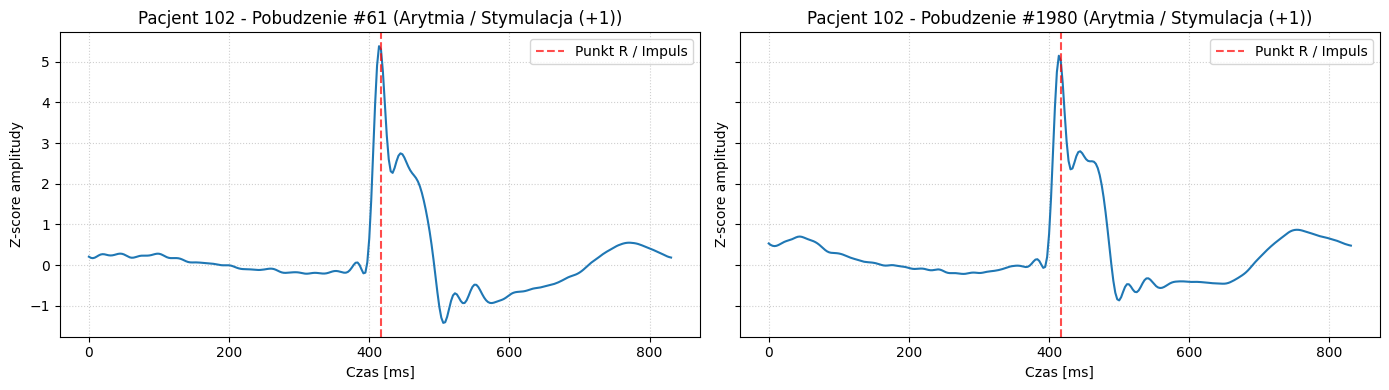

In [25]:
plot_random_beats_side_by_side(record_id='102')

### 5. Wplyw ksztaltu okna czasowego i kalibracji progu decyzyjnego

In [26]:
window_df = compare_window_shapes(SAMPLE_RECORDS, epochs=2, batch_size=128)
thresh_df, patient_err_df = evaluate_threshold_tuning(SAMPLE_RECORDS, epochs=2, return_breakdown=True)
display(window_df)
display(thresh_df)
display(patient_err_df)


--- Rozpoczynam Fold 1/4 ---
  Pacjenci weryfikacyjni: ['100']
  Wyniki foldu -> Acc: 0.210, Bal-Acc: 0.440, Czulosc (+1): 0.676, Specyficznosc (-1): 0.203

--- Rozpoczynam Fold 2/4 ---
  Pacjenci weryfikacyjni: ['102']
  Wyniki foldu -> Acc: 0.427, Bal-Acc: 0.700, Czulosc (+1): 0.400, Specyficznosc (-1): 1.000

--- Rozpoczynam Fold 3/4 ---
  Pacjenci weryfikacyjni: ['101']
  Wyniki foldu -> Acc: 0.168, Bal-Acc: 0.583, Czulosc (+1): 1.000, Specyficznosc (-1): 0.166

--- Rozpoczynam Fold 4/4 ---
  Pacjenci weryfikacyjni: ['104']
  Wyniki foldu -> Acc: 0.894, Bal-Acc: 0.499, Czulosc (+1): 0.999, Specyficznosc (-1): 0.000

--- Rozpoczynam Fold 1/4 ---
  Pacjenci weryfikacyjni: ['100']
  Wyniki foldu -> Acc: 0.985, Bal-Acc: 0.515, Czulosc (+1): 0.029, Specyficznosc (-1): 1.000

--- Rozpoczynam Fold 2/4 ---
  Pacjenci weryfikacyjni: ['102']
  Wyniki foldu -> Acc: 0.496, Bal-Acc: 0.735, Czulosc (+1): 0.471, Specyficznosc (-1): 1.000

--- Rozpoczynam Fold 3/4 ---
  Pacjenci weryfikacyjni: ['

,Ksztalt Okna,Model,Balansowanie,Accuracy,Balanced Accuracy,Czulosc (+1),Specyficznosc (-1),F1-Score (macro),MCC (Absolute)
0,Symetryczne okno (300 probek / 833 ms),CS-NET (CNN + SVM),Wlaczone (Resampling),0.4252 (+/- 0.3327),0.5555 (+/- 0.1127),0.7686 (+/- 0.2893),0.3424 (+/- 0.4472),0.2885 (+/- 0.1529),0.0612 (+/- 0.0753)
1,Asymetryczne QRS (-50 ms do +100 ms / 54 probki),CS-NET (CNN + SVM),Wlaczone (Resampling),0.8663 (+/- 0.2472),0.7343 (+/- 0.1951),0.4724 (+/- 0.3952),0.9961 (+/- 0.0058),0.6368 (+/- 0.2464),0.4070 (+/- 0.3637)
2,Asymetryczne QRS + Supresja iglicy,CS-NET (CNN + SVM),Wlaczone (Resampling),0.8033 (+/- 0.3761),0.6962 (+/- 0.2136),0.3926 (+/- 0.4272),0.9999 (+/- 0.0003),0.6161 (+/- 0.3062),0.4320 (+/- 0.3606)


,Prog SVM (score),Prawdopodobienstwo (P),Accuracy,Balanced Accuracy,Czulosc (+1),Specyficznosc (-1),F1-Score,MCC
0,0.2,0.55,78.14%,75.34%,50.68%,100.00%,0.7543,0.6032
1,0.0,0.50,92.27%,91.37%,83.38%,99.36%,0.9200,0.8498
2,-0.2,0.45,96.96%,97.04%,97.78%,96.31%,0.9693,0.9388
3,-0.4,0.40,95.79%,96.10%,98.91%,93.30%,0.9576,0.9172
4,-0.6,0.35,67.12%,70.39%,99.16%,41.61%,0.6563,0.4774


,Pacjent,Pobudzenia,Norma (-1),Arytmia (+1),TN,FP,FN,TP,Czulosc (+1),Specyficznosc (-1),Balanced Accuracy,MCC
0,100,2272,2238,34,2237,1,33,1,2.9%,100.0%,51.4%,0.1186
1,101,1865,1860,5,1858,2,3,2,40.0%,99.9%,69.9%,0.4459
2,102,2131,99,2032,99,0,37,1995,98.2%,100.0%,99.1%,0.8454
3,104,1563,163,1400,5,158,4,1396,99.7%,3.1%,51.4%,0.1124


### 6. Analiza waznosci cech elektrofizjologicznych i relacyjnych

In [27]:
group_imp_df = get_feature_importance_per_group(SAMPLE_PATIENT_GROUPS)
relational_imp_df = get_relational_qrs_importance_table(SAMPLE_RECORDS)
shuffle_df = run_permutation_shuffle_test(SAMPLE_RECORDS)
display(group_imp_df)
display(relational_imp_df)
display(shuffle_df)

,Cecha biomedyczna,ANOVA F (Standard (bez stymulatora)),ANOVA F (Pacemaker (ze stymulatorem))
0,Stosunek RR (Pre/Post),537.48,66.95
1,Pre-RR [s],275.99,275.91
2,Energia sygnalu pobudzenia,58.14,209.13
3,Pole zespolu QRS [mV·s],49.20,56.35
4,Post-RR [s],47.55,9.00
5,Srodek ciezkosci widma [Hz],38.49,346.29
6,Amplituda Vpp [mV],37.24,108.81
7,Skosnosc (Skewness),23.21,187.93
8,Udzial energii 4-15 Hz (QRS),14.60,4809.37
9,Dominujaca czestotliwosc [Hz],4.16,0.92


,Cecha relacyjna (okno 150 ms),Wskaznik ANOVA F,Wartosc p
0,Wariancja stromosci Var(dV/dt) [mV^2/s^2],15768.75,0.00e+00
1,Asymetria zbocza narastajacego do opadajacego,3634.86,0.00e+00
2,Szerokosc w polowie wysokosci (FWHM) [ms],264.22,1.85e-58
3,Pole pod zespolem QRS [mV·s],0.49,4.83e-01


,Cecha relacyjna,ANOVA F (Rzeczywiste y),ANOVA F (Permutacja losowa),Wartosc p (Permutacja),ANOVA F (Permutacja blokowa pacjentow)
0,Wariancja stromosci Var(dV/dt) [mV^2/s^2],15768.75,3.80,5.13e-02,16391.92
1,Asymetria zbocza narastajacego do opadajacego,3634.86,2.10,1.47e-01,2164.99
2,Szerokosc w polowie wysokosci (FWHM) [ms],264.22,0.40,5.30e-01,29.67
3,Pole pod zespolem QRS [mV·s],0.49,2.26,1.33e-01,41.78


### 7. Trening multimodalnego modelu CS-NET (Fale + 14 Cech)

In [28]:
X_w, X_f, y_all, grp_all = build_multimodal_dataset_with_groups(SAMPLE_RECORDS)
hybrid_df, hybrid_model, (y_test, y_pred) = evaluate_hybrid_feature_csnet(
    X_w, X_f, y_all, grp_all, n_splits=len(set(grp_all)), epochs=3, batch_size=128
)
hybrid_df


--- Hybrydowy CS-NET: Fold 1/4 ---
  Wyniki foldu -> Acc: 0.985, Bal-Acc: 0.514, Czulosc (+1): 0.029, Specyficznosc (-1): 1.000

--- Hybrydowy CS-NET: Fold 2/4 ---
  Wyniki foldu -> Acc: 0.672, Bal-Acc: 0.429, Czulosc (+1): 0.697, Specyficznosc (-1): 0.162

--- Hybrydowy CS-NET: Fold 3/4 ---
  Wyniki foldu -> Acc: 0.592, Bal-Acc: 0.795, Czulosc (+1): 1.000, Specyficznosc (-1): 0.590

--- Hybrydowy CS-NET: Fold 4/4 ---
  Wyniki foldu -> Acc: 0.555, Bal-Acc: 0.676, Czulosc (+1): 0.523, Specyficznosc (-1): 0.828


,Model,Balansowanie,Accuracy,Balanced Accuracy,Czulosc (+1),Specyficznosc (-1),F1-Score (macro),MCC (Absolute)
0,Hybrydowy CS-NET (Fale + 13 Cech),Wlaczone (Resampling),0.7009 (+/- 0.1957),0.6036 (+/- 0.1635),0.5623 (+/- 0.4063),0.6450 (+/- 0.3633),0.4509 (+/- 0.0639),0.1152 (+/- 0.0713)


### 8. Ewaluacja i wyjasnialnosc modelu (Macierz pomylek i 1D Grad-CAM)

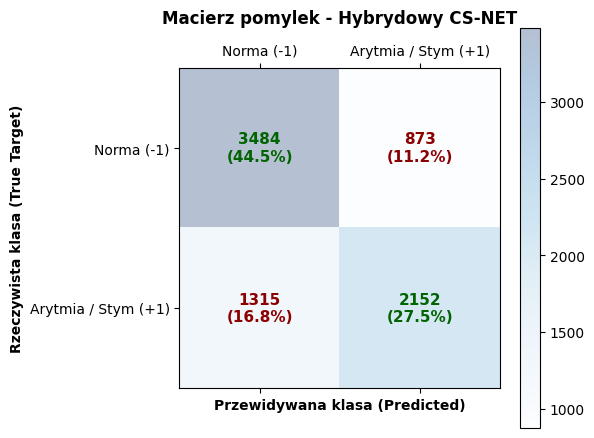

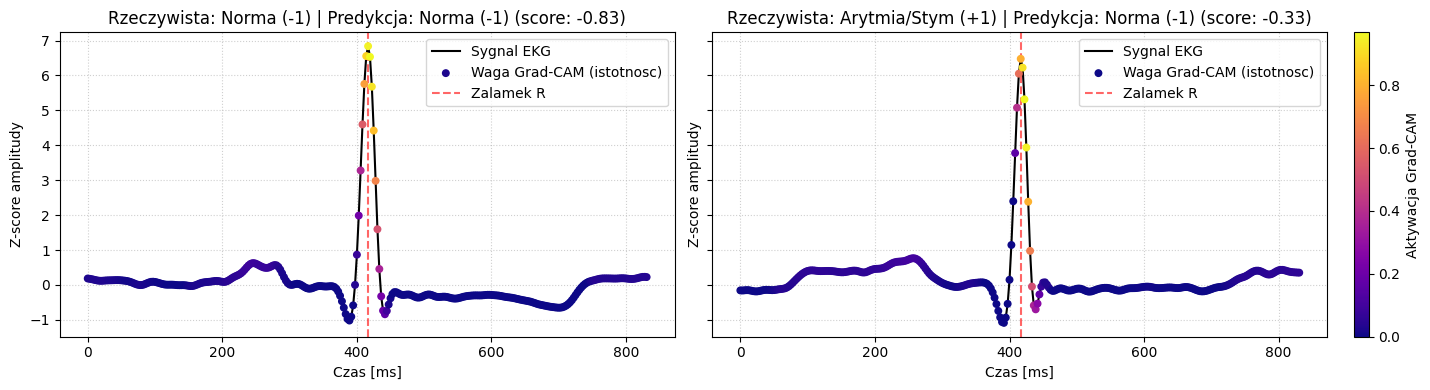

In [29]:
plot_confusion_matrix(y_test, y_pred, title='Macierz pomylek - Hybrydowy CS-NET')
plot_model_explanations(hybrid_model, X_w, y_all)

### 9. Osobny trening i ewaluacja dla grup pacjentow (GroupKFold)

In [30]:
results_df = evaluate_by_patient_groups(SAMPLE_PATIENT_GROUPS, epochs=3, batch_size=128)
results_df


 Trening dla grupy: Standard (bez stymulatora) (liczba rekordow: 2) | Balans: True

--- Rozpoczynam Fold 1/2 ---
  Pacjenci weryfikacyjni: ['100']
  Wyniki foldu -> Acc: 0.971, Bal-Acc: 0.725, Czulosc (+1): 0.471, Specyficznosc (-1): 0.979

--- Rozpoczynam Fold 2/2 ---
  Pacjenci weryfikacyjni: ['101']
  Wyniki foldu -> Acc: 0.842, Bal-Acc: 0.621, Czulosc (+1): 0.400, Specyficznosc (-1): 0.843

 Trening dla grupy: Pacemaker (ze stymulatorem) (liczba rekordow: 2) | Balans: True

--- Rozpoczynam Fold 1/2 ---
  Pacjenci weryfikacyjni: ['102']
  Wyniki foldu -> Acc: 0.922, Bal-Acc: 0.517, Czulosc (+1): 0.964, Specyficznosc (-1): 0.071

--- Rozpoczynam Fold 2/2 ---
  Pacjenci weryfikacyjni: ['104']
  Wyniki foldu -> Acc: 0.890, Bal-Acc: 0.502, Czulosc (+1): 0.992, Specyficznosc (-1): 0.012


,Grupa Pacjentow,Balansowanie,Pobudzenia,Accuracy,Balanced Accuracy,Czulosc (+1),Specyficznosc (-1),F1-Score (macro),MCC (Absolute)
0,Standard (bez stymulatora),Wlaczone (Resampling),4135,0.9063 (+/- 0.0914),0.6730 (+/- 0.0729),0.4353 (+/- 0.0499),0.9107 (+/- 0.0959),0.5598 (+/- 0.1359),0.1820 (+/- 0.2087)
1,Pacemaker (ze stymulatorem),Wlaczone (Resampling),3690,0.9059 (+/- 0.0228),0.5097 (+/- 0.0106),0.9778 (+/- 0.0202),0.0415 (+/- 0.0413),0.5004 (+/- 0.0257),0.0263 (+/- 0.0162)
